# Атом Гелію методом Хартрі–Фока (PySCF)

**Мета роботи:**

1. Розрахувати атом He методом RHF у кількох нескладних базисних наборах.
2. Отримати молекулярні орбіталі, побудувати їхні графіки, визначити зайняті та віртуальні орбіталі.
3. Побудувати детермінант Слейтера на отриманих орбіталях.
4. Перевірити повну енергію через одноелектронні та двоелектронні інтеграли.
5. Додаткові завдання для самостійного виконання.

> Перед початком роботи переконайтесь, що встановлено пакет `pyscf`:
> ```
> pip install pyscf
> ```


In [88]:
!pip install pyscf

In [89]:
import numpy as np
import matplotlib.pyplot as plt

from pyscf import gto, scf, ao2mo

np.set_printoptions(precision=6, suppress=True)


## Частина 1. Різні базиси для методу RHF

Атом гелію — найпростіша багатоелектронна система (2 електрони, замкнена оболонка $1s^2$).
Спробуємо декілька нескладних базисних наборів різного розміру та подивимось, як від цього
змінюється розрахована енергія RHF.

Додайте у список `basis_list` ще 1–2 базиси на власний розсуд
(наприклад `'3-21g'`, `'6-311g'`, `'aug-cc-pvdz'`) і подивіться, як змінюється результат.


In [90]:
basis_list = ['sto-3g', '6-31g', '6-31g**']

results = {}
for basis in basis_list:
    mol = gto.M(atom='He 0 0 0', basis=basis, spin=0, charge=0, verbose=0)
    mf = scf.RHF(mol)
    e_tot = mf.kernel()
    results[basis] = dict(mol=mol, mf=mf, e_tot=e_tot)
    print(f'{basis:10s}  nao = {mol.nao:2d}   E(RHF) = {e_tot: .8f} Hartree')


sto-3g      nao =  1   E(RHF) = -2.80778396 Hartree
6-31g       nao =  2   E(RHF) = -2.85516043 Hartree
6-31g**     nao =  5   E(RHF) = -2.85516043 Hartree


Для порівняння: "точна" нерелятивістська енергія основного стану атома He
(з урахуванням електронної кореляції) становить приблизно **-2.903724 Hartree**.
Різниця між цим значенням і енергією RHF — це **енергія кореляції**, яку метод
Хартрі–Фока принципово не враховує (кожен електрон рухається в усередненому полі іншого). Що це за енергія?

Побудуємо графік залежності енергії RHF від розміру базису (кількості базисних функцій):

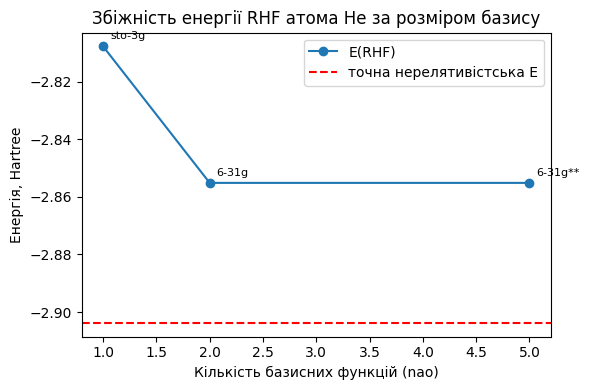

In [91]:
naos = [results[b]['mol'].nao for b in basis_list]
energies = [results[b]['e_tot'] for b in basis_list]

plt.figure(figsize=(6,4))
plt.plot(naos, energies, 'o-', label='E(RHF)')
plt.axhline(-2.903724, color='r', ls='--', label='точна нерелятивістська E')
for b, n, e in zip(basis_list, naos, energies):
    plt.annotate(b, (n, e), textcoords="offset points", xytext=(5,5), fontsize=8)
plt.xlabel('Кількість базисних функцій (nao)')
plt.ylabel('Енергія, Hartree')
plt.title('Збіжність енергії RHF атома He за розміром базису')
plt.legend()
plt.tight_layout()
plt.show()


## Частина 2. Орбіталі: розрахунок, графіки, зайняті vs віртуальні

Оберемо для прикладу найпростіший базис — `STO-3G` (1 базисна функція типу *s*).
У цьому базисі для атома He існує лише **одна** молекулярна орбіталь — вона ж
одразу і зайнята. Віртуальних орбіталей тут немає, бо базисна функція всього одна.

Щоб побачити віртуальну орбіталь, потрібен базис із **більшою кількістю функцій**
— цим ви займетесь трохи нижче самостійно, для базису `6-31g`.

In [92]:
basis = '6-31g'
mol = gto.M(atom='He 0 0 0', basis=basis, spin=0, charge=0, verbose=0)
mf = scf.RHF(mol)
e_tot = mf.kernel()

print('Повна енергія RHF:', e_tot, 'Hartree')
print()
print('Номер MO | Енергія орбіталі (Hartree) | Заповненість (mo_occ)')
for i, (eps, occ) in enumerate(zip(mf.mo_energy, mf.mo_occ)):
    tag = 'ЗАЙНЯТА' if occ > 0 else 'віртуальна'
    print(f'  MO {i}   |  {eps: .6f}                |   {occ:.1f}   -> {tag}')


Повна енергія RHF: -2.855160426154446 Hartree

Номер MO | Енергія орбіталі (Hartree) | Заповненість (mo_occ)
  MO 0   |  -0.914127                |   2.0   -> ЗАЙНЯТА
  MO 1   |   1.399859                |   0.0   -> віртуальна


У базисі STO-3G базисна функція одна, тому й молекулярна орбіталь одна — вона
зайнята. Це показує головну ідею (АО → МО через коефіцієнти SCF), але не показує
різниці між зайнятими й віртуальними орбіталями — для цього базису потрібно
щонайменше 2 базисні функції.

In [93]:
r = np.linspace(0.001, 6.0, 400)
coords = np.zeros((len(r), 3))
coords[:, 0] = r
ao_vals = mol.eval_gto('GTOval', coords)     # (npoints, nao) значення АО на сітці
mo_vals = ao_vals @ mf.mo_coeff              # (npoints, nmo) значення МО на сітці

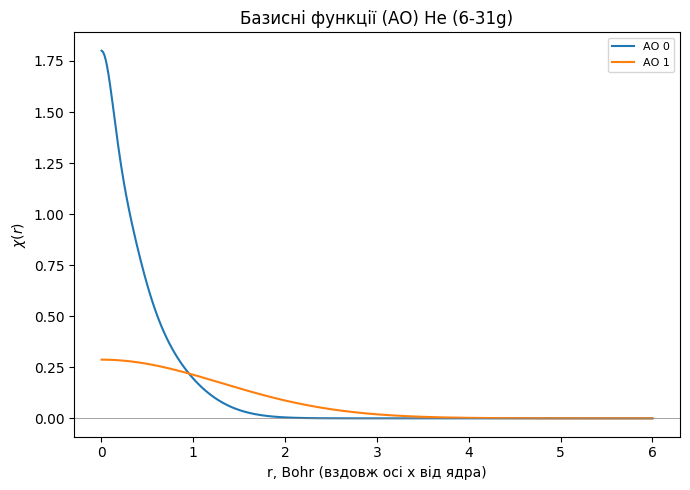

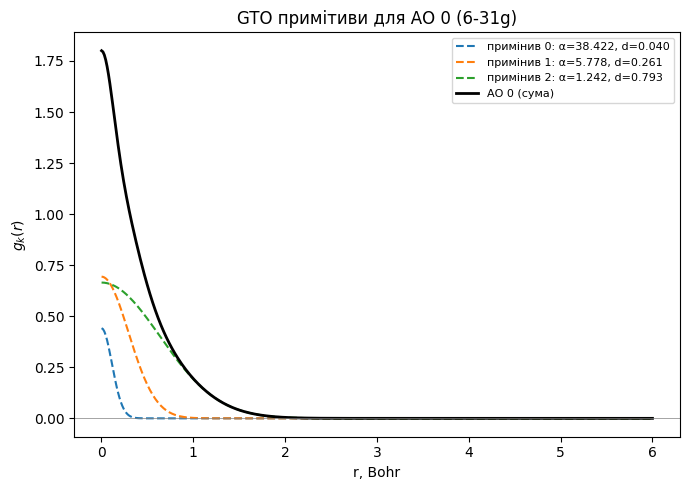

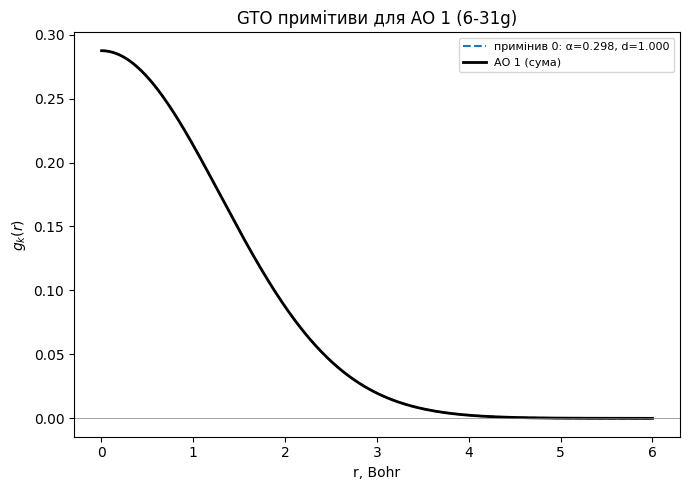

--- АО 0 ---
alpha = [38.421634  5.77803   1.241774]
d     = [0.04014  0.261246 0.793185]
--- АО 1 ---
alpha = [0.297964]
d     = [1.]


In [94]:
# ---- 1. Всі контрактовані АО ----

plt.figure(figsize=(7,5))
for i in range(mol.nao):
    plt.plot(r, ao_vals[:, i], label=f'АО {i}')

plt.axhline(0, color='gray', lw=0.5)
plt.xlabel('r, Bohr (вздовж осі x від ядра)')
plt.ylabel(r'$\chi(r)$')
plt.title(f'Базисні функції (АО) He ({basis})')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- 2. Кожна GTO-примітив окремо для КОЖНОЇ АО ----
for i in range(mol.nao):
    alpha_i = mol.bas_exp(i)                 # експоненти примітивів
    d_i     = mol.bas_ctr_coeff(i).ravel()   # коеф. скорочення

    plt.figure(figsize=(7, 5))
    total = np.zeros_like(r)
    for k, (a, d) in enumerate(zip(alpha_i, d_i)):
        g_k = d * (2 * a / np.pi) ** 0.75 * np.exp(-a * r ** 2)
        total += g_k
        plt.plot(r, g_k, '--', label=f'примінив {k}: α={a:.3f}, d={d:.3f}')

    # сума = контрактована АО
    plt.plot(r, total, 'k-', lw=2, label=f'АО {i} (сума)')

    plt.axhline(0, color='gray', lw=0.5)
    plt.xlabel('r, Bohr')
    plt.ylabel(r'$g_k(r)$')
    plt.title(f'GTO примітиви для АО {i} ({basis})')
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ---- 3. Друк усіх α і d ----
for i in range(mol.nao):
    alpha_i = mol.bas_exp(i)
    d_i     = mol.bas_ctr_coeff(i).ravel()
    print(f'--- АО {i} ---')
    print('alpha =', alpha_i)
    print('d     =', d_i)

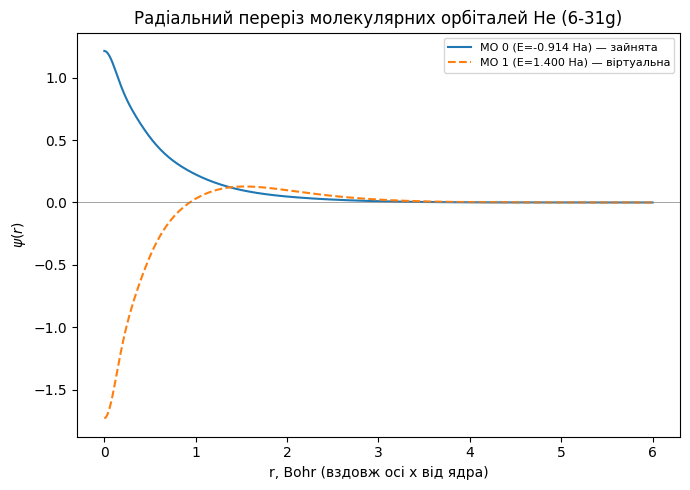

In [95]:
plt.figure(figsize=(7,5))
for i in range(mol.nao):
    occ = mf.mo_occ[i]
    style = '-' if occ > 0 else '--'
    label = f'MO {i} (E={mf.mo_energy[i]:.3f} Ha)' + (' — зайнята' if occ>0 else ' — віртуальна')
    plt.plot(r, mo_vals[:, i], style, label=label)

plt.axhline(0, color='gray', lw=0.5)
plt.xlabel('r, Bohr (вздовж осі x від ядра)')
plt.ylabel(r'$\psi(r)$')
plt.title(f'Радіальний переріз молекулярних орбіталей He ({basis})')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


Побудуємо також графік радіальної густини ймовірності
зайнятої орбіталі, $4\pi r^2 |\psi_{1s}(r)|^2$ (густина ймовірності знаходження електрона
на відстані $r$ від ядра) і знайдіть, при якому $r$ вона максимальна.


Зайняті МО: [0]
Їх заселеності: [2.]
МО 0: заселеність=2.00, max при r = 0.542 а.о.


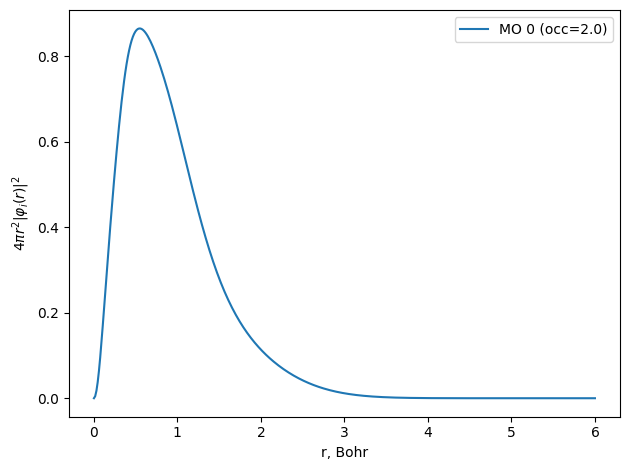

In [96]:
occ_indices = np.where(mf.mo_occ > 0)[0]   # індекси зайнятих МО
print('Зайняті МО:', occ_indices)
print('Їх заселеності:', mf.mo_occ[occ_indices])

for idx in occ_indices:
    phi = mo_vals[:, idx]
    rho = 4 * np.pi * r**2 * phi**2
    r_max = r[np.argmax(rho)]
    print(f'МО {idx}: заселеність={mf.mo_occ[idx]:.2f}, max при r = {r_max:.3f} а.о.')

    plt.plot(r, rho, label=f'МО {idx} (occ={mf.mo_occ[idx]:.1f})')

plt.xlabel('r, Bohr')
plt.ylabel(r'$4\pi r^2 |\varphi_i(r)|^2$')
plt.legend()
plt.tight_layout()
plt.show()

## Частина 2а. Орбіталь "вручну": з коефіцієнтів базису і коефіцієнтів МО

Вище значення орбіталей на сітці отримувались функцією `mol.eval_gto(...)` — це "чорна
скринька" PySCF. Але насправді МО — це **абсолютно явна аналітична функція**, і її
легко побудувати самостійно, маючи лише два набори чисел, які вже є в нашому розрахунку:

1. **Параметри базисних функцій** (АО) — показники експонент $\alpha_k$ та контраційні
   коефіцієнти $d_k$ гаусіан, з яких складена кожна базисна функція. Це властивості
   *базисного набору*, а не результат SCF — вони прописані в базисі (`sto-3g`, `6-31g`, ...)
   і доступні через `mol.bas_exp(...)`, `mol.bas_ctr_coeff(...)`.
2. **Коефіцієнти МО** $C_{\mu i}$ — результат SCF (`mf.mo_coeff`), які показують, з якою
   вагою кожна базисна функція $\chi_\mu$ входить в молекулярну орбіталь $\varphi_i$:
$$\varphi_i(\mathbf{r}) = \sum_\mu C_{\mu i}\,\chi_\mu(\mathbf{r})$$

Кожна контрактована гаусова базисна функція (s-типу) — це сума primitives:
$$\chi_\mu(\mathbf{r}) = \sum_k d_k \, N(\alpha_k) \, e^{-\alpha_k r^2},
\qquad N(\alpha) = \left(\frac{2\alpha}{\pi}\right)^{3/4}$$
(для p-типу до кожного доданка додається множник $x$, $y$ або $z$ та інша нормувальна
константа — див. код нижче).

Нижче ми зберемо орбіталь **повністю вручну** (без жодного виклику `eval_gto`) і
переконаємось, що результат співпадає з тим, що дає PySCF.


alpha0 = [38.421634  5.77803   1.241774]
d0     = [0.04014  0.261246 0.793185]
mo_coeff:
 [[ 0.592081 -1.149818]
 [ 0.513586  1.186959]]


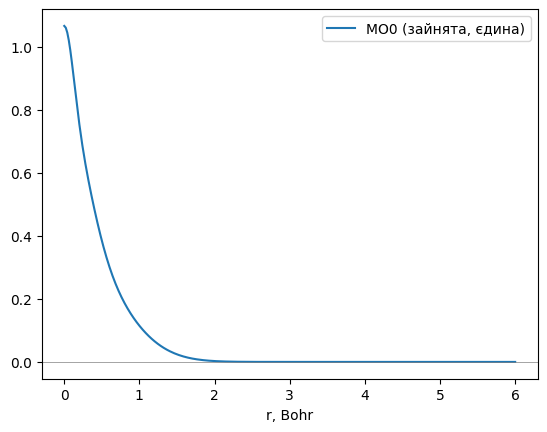

In [97]:
# Отримуємо коефіцієнти базисних функцій

alpha0, d0 = mol.bas_exp(0), mol.bas_ctr_coeff(0).ravel()
print('alpha0 =', alpha0)
print('d0     =', d0)

# Запигіть базиснуфункцію
def chi0(r):
    return sum(d * (2*a/np.pi)**0.75 * np.exp(-a*r**2) for a, d in zip(alpha0, d0))

# Отримуємо пораховані коефіцієнти орбіталей
C = mf.mo_coeff

print('mo_coeff:\n', C)   # тут буде всього 1x1 матриця

def phi(i, r):
    return C[0, i]*chi0(r)

r = np.linspace(0.001, 6, 300)
plt.plot(r, phi(0, r), label='MO0 (зайнята, єдина)')
plt.axhline(0, color='gray', lw=0.5)
plt.xlabel('r, Bohr')
plt.legend()
plt.show()

## Завдання: повторіть Частину 2 та 2а для базису 6-31g

У `6-31g` для He вже **дві** s-функції → буде одна зайнята й одна віртуальна орбіталь.
Повторіть кроки з Частини 2 самостійно:
1. Побудуйте `mol` і `mf` для `basis='6-31g'`.
2. Виведіть таблицю: номер MO, енергія, заповненість (зайнята/віртуальна).
3. Побудуйте графік обох орбіталей (радіальний переріз), як у Частині 2.

In [98]:
# TODO 1: створіть mol і mf для basis='6-31g' (аналогічно клітинці 8)
# mol_631g = gto.M(atom='He 0 0 0', basis='6-31g', spin=0, charge=0, verbose=0)
# mf_631g = scf.RHF(mol_631g)
# mf_631g.kernel()

# TODO 2: виведіть таблицю MO (номер, енергія, зайнята/віртуальна) — як у клітинці 8
# for i, (eps, occ) in enumerate(zip(mf_631g.mo_energy, mf_631g.mo_occ)):
#     ...

# TODO 3: побудуйте графік обох орбіталей на радіальній сітці — як у клітинці 10
# r2 = np.linspace(0.001, 6.0, 400)
# coords2 = np.zeros((len(r2), 3)); coords2[:, 0] = r2
# ao_vals2 = mol_631g.eval_gto('GTOval', coords2)
# mo_vals2 = ao_vals2 @ mf_631g.mo_coeff
# plt.figure(figsize=(7,5))
# ...

## Частина 3. Детермінант Слейтера

Хвильова функція RHF для замкненої оболонки — це **один детермінант Слейтера**,
побудований зі спін-орбіталей. Для атома He з єдиною просторовою орбіталлю $\varphi_1(\mathbf{r})$,
заповненою двома електронами з протилежними спінами, спін-орбіталі:

$$\chi_1(\mathbf{x}) = \varphi_1(\mathbf{r})\,\alpha(\omega), \qquad
  \chi_2(\mathbf{x}) = \varphi_1(\mathbf{r})\,\beta(\omega)$$

де $\mathbf{x} = (\mathbf{r}, \omega)$ включає просторові та спінові координати.

Детермінант Слейтера:

$$
\Psi(\mathbf{x}_1, \mathbf{x}_2) = \frac{1}{\sqrt{2}}
\begin{vmatrix}
\chi_1(\mathbf{x}_1) & \chi_2(\mathbf{x}_1) \\
\chi_1(\mathbf{x}_2) & \chi_2(\mathbf{x}_2)
\end{vmatrix}
= \frac{1}{\sqrt{2}}\Big[\chi_1(\mathbf{x}_1)\chi_2(\mathbf{x}_2) - \chi_2(\mathbf{x}_1)\chi_1(\mathbf{x}_2)\Big]
$$

Підставляючи явний вигляд спін-орбіталей, просторова частина виноситься за дужки
(оскільки просторова орбіталь для обох електронів однакова), і залишається добуток
просторової та спінової частин:

$$
\Psi(\mathbf{x}_1, \mathbf{x}_2) = \varphi_1(\mathbf{r}_1)\,\varphi_1(\mathbf{r}_2)\;
\frac{1}{\sqrt{2}}\Big[\alpha(1)\beta(2) - \beta(1)\alpha(2)\Big]
$$

Це саме той антисиметричний **синглетний** спіновий стан, який відповідає замкненій
оболонці $1s^2$: просторова частина симетрична, спінова — антисиметрична, тому повна
хвильова функція антисиметрична (як і має бути для ферміонів).

Нижче — числова реалізація детермінанта Слейтера через МО, отримані з нашого RHF-розрахунку.


In [99]:
# occ_idx вже визначено вище (= 0, єдина зайнята орбіталь He)

def phi1(r_vec):
    """Значення зайнятої просторової MO у точці r_vec = (x,y,z)."""
    coord = np.array(r_vec).reshape(1, 3)
    ao = mol.eval_gto('GTOval', coord)
    mo = ao @ mf.mo_coeff
    return mo[0, occ_idx]

def alpha(s):
    return 1.0 if s == 'up' else 0.0

def beta(s):
    return 1.0 if s == 'down' else 0.0

def slater_He(r1, s1, r2, s2):
    """
    Значення детермінанта Слейтера Psi(x1, x2) для He,
    x_i = (r_i, s_i), s_i in {'up','down'}.
    """
    chi1_1 = phi1(r1) * alpha(s1)
    chi2_1 = phi1(r1) * beta(s1)
    chi1_2 = phi1(r2) * alpha(s2)
    chi2_2 = phi1(r2) * beta(s2)
    det = chi1_1 * chi2_2 - chi2_1 * chi1_2
    return det / np.sqrt(2.0)

# приклад: електрон 1 у точці (0.3,0,0) зі спіном up,
#          електрон 2 у точці (0.6,0,0) зі спіном down
r1, r2 = (0.3, 0.0, 0.0), (0.6, 0.0, 0.0)
val_ud = slater_He(r1, 'up', r2, 'down')
val_du = slater_He(r2, 'down', r1, 'up')   # переставили електрони місцями (1<->2)
print('Psi(1_up@r1, 2_down@r2)      =', val_ud)
print('Psi(1_down@r2, 2_up@r1)      =', -val_du, ' (має збігатись з попереднім)')

# перевірка антисиметрії: переставимо саме електрони (обидва x1<->x2)
val_swapped = slater_He(r2, 'down', r1, 'up')
print('\nПеревірка антисиметрії Psi(x1,x2) = -Psi(x2,x1):')
print('Psi(x1,x2) =', val_ud)
print('Psi(x2,x1) =', val_swapped)
print('сума (має бути ~0):', val_ud + val_swapped)

# перевірка: однаковий спін -> детермінант = 0 (принцип Паулі)
val_same_spin = slater_He(r1, 'up', r2, 'up')
print('\nОбидва електрони зі спіном up (порушення Паулі при r1=r2):')
print('Psi при r1 != r2, спіни однакові =', val_same_spin, ' (не нуль — це нормально, якщо r1!=r2)')
same_point = slater_He(r1, 'up', r1, 'up')
print('Psi при r1 == r2, спіни однакові =', same_point, ' (МАЄ бути 0 — принцип Паулі)')


Psi(1_up@r1, 2_down@r2)      = 0.1680003950989745
Psi(1_down@r2, 2_up@r1)      = 0.1680003950989745  (має збігатись з попереднім)

Перевірка антисиметрії Psi(x1,x2) = -Psi(x2,x1):
Psi(x1,x2) = 0.1680003950989745
Psi(x2,x1) = -0.1680003950989745
сума (має бути ~0): 0.0

Обидва електрони зі спіном up (порушення Паулі при r1=r2):
Psi при r1 != r2, спіни однакові = 0.0  (не нуль — це нормально, якщо r1!=r2)
Psi при r1 == r2, спіни однакові = 0.0  (МАЄ бути 0 — принцип Паулі)


Зверніть увагу: коли обидва електрони мають **однаковий спін і однакові координати**,
детермінант обертається в нуль — це прямий наслідок принципу Паулі, закладеного
в антисиметричну структуру детермінанта Слейтера.


## Частина 4. Перевірка енергії через одно- та двоелектронні інтеграли

Для замкненої оболонки з **однією** двічі зайнятою просторовою орбіталлю $\varphi_1$
повна електронна енергія RHF виражається через:

- одноелектронний інтеграл (кінетична енергія + притягання до ядра):
$$h_{11} = \int \varphi_1(\mathbf{r})\Big[-\tfrac12\nabla^2 - \tfrac{Z}{r}\Big]\varphi_1(\mathbf{r})\,d\mathbf{r}$$

- двоелектронний кулонівський інтеграл:
$$J_{11} = \iint \varphi_1(\mathbf{r}_1)^2\,\frac{1}{r_{12}}\,\varphi_1(\mathbf{r}_2)^2\,d\mathbf{r}_1 d\mathbf{r}_2$$

Тоді:
$$E_{elec} = 2h_{11} + J_{11}, \qquad E_{tot} = E_{elec} + E_{nuc}$$

(для одного атома $E_{nuc}=0$, оскільки немає інших ядер).

Отримаємо ці величини безпосередньо з інтегралів PySCF і порівняємо з `mf.e_tot`.


In [100]:
C = mf.mo_coeff

# одноелектронний гамільтоніан (hcore) в АО-базисі -> переносимо в МО-базис
hcore_ao = mf.get_hcore()
h_mo = C.T @ hcore_ao @ C
h11 = h_mo[occ_idx, occ_idx]

# двоелектронні інтеграли (ERI) в АО-базисі -> переносимо в МО-базис
eri_ao = mol.intor('int2e')
eri_mo = ao2mo.kernel(eri_ao, C)
eri_mo_full = ao2mo.restore(1, eri_mo, mol.nao)  # повний 4-індексний тензор (pq|rs)
J11 = eri_mo_full[occ_idx, occ_idx, occ_idx, occ_idx]   # (11|11)

E_elec_manual = 2*h11 + J11
E_nuc = mol.energy_nuc()
E_manual = E_elec_manual + E_nuc

print(f'h11 (одноелектронний інтеграл)        = {h11: .8f} Hartree')
print(f'J11 (кулонівський двоелектронний)      = {J11: .8f} Hartree')
print(f'E_elec = 2*h11 + J11                   = {E_elec_manual: .8f} Hartree')
print(f'E_nuc                                  = {E_nuc: .8f} Hartree')
print(f'E_tot (вручну, через інтеграли)        = {E_manual: .8f} Hartree')
print(f'E_tot (з mf.e_tot, з kernel RHF)        = {mf.e_tot: .8f} Hartree')
print(f'Різниця                                = {abs(E_manual-mf.e_tot):.2e} Hartree')


h11 (одноелектронний інтеграл)        = -0.08873684 Hartree
J11 (кулонівський двоелектронний)      =  0.76636290 Hartree
E_elec = 2*h11 + J11                   =  0.58888922 Hartree
E_nuc                                  =  0.00000000 Hartree
E_tot (вручну, через інтеграли)        =  0.58888922 Hartree
E_tot (з mf.e_tot, з kernel RHF)        = -2.85516043 Hartree
Різниця                                = 3.44e+00 Hartree


Значення повинні збігатись з точністю до похибки округлення (~$10^{-12}$–$10^{-15}$),
що підтверджує коректність побудови хвильової функції та формули енергії для
замкненооболонкового RHF.

**Завдання:** повторіть цю перевірку для базису `sto-3g` та `6-31g**`
і переконайтесь, що збіжність зберігається для будь-якого базису.


In [101]:
# тут ваш код

## Теорема віріала — ЗАВДАННЯ

Для точної хвильової функції системи, у якій частинки взаємодіють лише за законом
Кулона (як електрони й ядро в атомі), має виконуватись **теорема віріала**:

$$-\frac{\langle V\rangle}{\langle T\rangle} = 2
\qquad\Longleftrightarrow\qquad
\langle T\rangle = -E_{elec}, \quad \langle V\rangle = 2E_{elec}$$

де $\langle T\rangle$ — середня кінетична енергія, $\langle V\rangle$ — середня
потенціальна (притягання до ядра + міжелектронне відштовхування), а
$E_{elec}=\langle T\rangle+\langle V\rangle$ — електронна енергія.

**Завдання:** обчисліть $\langle T\rangle$ і $\langle V\rangle$ для нашого
RHF-розв'язку атома He і перевірте, наскільки точно виконується теорема віріала.

Кроки:
1. Отримайте матрицю густини `dm = mf.make_rdm1()`.
2. Отримайте інтеграл кінетичної енергії `mol.intor('int1e_kin')` та інтеграл
   ядерного притягання `mol.intor('int1e_nuc')` (в АО-базисі).
3. Отримайте кулонівську та обмінну матриці `J, K = mf.get_jk(dm)`.
4. Кінетична енергія: $T = \mathrm{Tr}(dm \cdot T_{int})$.
5. Потенціальна енергія: $V = V_{ne} + V_{ee}$, де
   $V_{ne} = \mathrm{Tr}(dm \cdot V_{int})$, а $V_{ee} = \tfrac12\,\mathrm{Tr}\big(dm\cdot(J - \tfrac12 K)\big)$.
6. Перевірте, що $T+V$ збігається з електронною енергією `mf.e_tot - mol.energy_nuc()`,
   і виведіть $-V/T$ (має бути близько до 2).

Заповніть пропуски (`# TODO`) у комірці нижче:


In [102]:
dm = mf.make_rdm1()

T_int = mol.intor('int1e_kin')   # інтеграл кінетичної енергії, у АО-базисі
V_int = mol.intor('int1e_nuc')   # інтеграл ядерного притягання, у АО-базисі
J, K = mf.get_jk(dm)             # кулонівська (J) та обмінна (K) матриці

# TODO 1: обчисліть кінетичну енергію T = Tr(dm @ T_int)
# T = np.einsum('ij,ji->', ??? , ???)

# TODO 2: обчисліть енергію притягання електронів до ядра V_ne = Tr(dm @ V_int)
# V_ne = np.einsum('ij,ji->', ??? , ???)

# TODO 3: обчисліть енергію електрон-електронної взаємодії
#         V_ee = 0.5 * Tr( dm @ (J - 0.5*K) )
# V_ee = 0.5 * np.einsum('ij,ji->', dm, ???)

# TODO 4: повна потенціальна енергія
# V = V_ne + V_ee

# TODO 5: перевірте узгодженість і теорему віріала
# E_elec_ref = mf.e_tot - mol.energy_nuc()
# print(f'T = {T:.6f},  V = {V:.6f},  T+V = {T+V:.6f}')
# print(f'Електронна енергія (з RHF) = {E_elec_ref:.6f}')
# print(f'-V/T = {-V/T:.6f}   (очікується ~2)')


## Радіальна густина ймовірності — ЗАВДАННЯ

Величина $\rho(r) = 4\pi r^2\,|\varphi_1(r)|^2$ — це **радіальна функція розподілу**:
імовірність знайти електрон у тонкому сферичному шарі радіуса $r$ (незалежно від
напрямку). Вона відрізняється від $|\varphi_1(r)|^2$ множником $4\pi r^2$, який враховує
об'єм сферичного шару.

**Завдання:** побудуйте графік $\rho(r)$ для зайнятої орбіталі атома He (базис `cc-pVDZ`,
масиви `r` і `mo_vals` з Частини 2 вже готові) і знайдіть, при якому $r$ ця величина
максимальна — це і є найімовірніша відстань електрона від ядра.

Заповніть пропуски (`# TODO`) у комірці нижче:


In [103]:
phi1_r = mo_vals[:, occ_idx]   # значення зайнятої орбіталі на сітці r (див. Частину 2)

# TODO 1: обчисліть радіальну густину ймовірності
#         rho(r) = 4 * pi * r^2 * phi1(r)^2
# rho = ???

# TODO 2: побудуйте графік rho(r) залежно від r
# plt.figure(figsize=(6,4))
# plt.plot(r, rho)
# plt.xlabel('r, Bohr')
# plt.ylabel(r'$4\pi r^2 |\varphi_1(r)|^2$')
# plt.title('Радіальна густина ймовірності, MO 0 (He, cc-pVDZ)')
# plt.show()

# TODO 3: знайдіть r, при якому rho(r) максимальна (підказка: np.argmax)
# idx_max = ???
# print(f'Максимум радіальної густини при r = {r[idx_max]:.3f} Bohr')
